# TelcoPeople — Départs visibles, départs silencieux et modèle hybride

Ce notebook combine les deux enrichissements les plus crédibles obtenus jusqu’ici :

- les variables continues issues de la segmentation et de la détection d’anomalies ;
- les quatre signaux comportementaux réellement utilisés par le modèle.

L’objectif est aussi de distinguer deux formes de départ :

1. **départ visible** : faible engagement, position salariale défavorable, stagnation ou profil atypique ;
2. **départ silencieux** : départ réel sans signaux négatifs évidents dans les variables disponibles.

La validation reste strictement temporelle : apprentissage avant juin 2024, validation sur juin 2024.

## 1. Importation des bibliothèques

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    roc_auc_score, classification_report, confusion_matrix
)
from catboost import CatBoostClassifier

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

## 2. Chargement des données

In [2]:
CHEMIN = "../data/raw/"
train = pd.read_csv(CHEMIN + "telcopeople_train.csv")
test = pd.read_csv(CHEMIN + "telcopeople_test.csv")

print("Train :", train.shape)
print("Test :", test.shape)
print("Taux global de départ :", round(train["target"].mean() * 100, 2), "%")

Train : (5444, 42)
Test : (1507, 41)
Taux global de départ : 10.14 %


## 3. Préparation métier commune

La fonction crée les variables temporelles, salariales, d’engagement, de performance et d’absentéisme utilisées dans les analyses précédentes.

In [3]:
def preparer_donnees(df):
    df = df.copy()

    df["ville_affectation"] = df["ville_affectation"].fillna("INCONNU").str.strip().str.title()
    df["departement"] = df["departement"].fillna("INCONNU").str.strip().str.upper().str.replace("DEPT", "DEP", regex=False)
    df["contrat"] = df["contrat"].fillna("INCONNU").str.strip().str.upper().str.replace(".", "", regex=False)
    df["niveau_etude"] = (
        df["niveau_etude"].fillna("INCONNU").str.strip().str.upper()
        .str.replace(" ", "", regex=False).str.replace("BAC2", "BAC+2", regex=False)
    )
    for col in ["genre", "poste", "grade", "code_site", "source_sirh"]:
        df[col] = df[col].fillna("INCONNU").astype(str).str.strip().str.upper()

    dates = ["date_reference", "date_naissance", "date_embauche", "date_derniere_promotion", "date_derniere_absence"]
    for col in dates:
        df[col] = pd.to_datetime(df[col], format="mixed", dayfirst=True, errors="coerce")

    df["salaire_mensuel"] = pd.to_numeric(
        df["salaire_mensuel"].astype(str).str.replace("FCFA", "", regex=False).str.replace(" ", "", regex=False),
        errors="coerce"
    )

    df["age"] = (df["date_reference"] - df["date_naissance"]).dt.days / 365.25
    df["anciennete"] = (df["date_reference"] - df["date_embauche"]).dt.days / 365.25
    df["annees_depuis_promotion"] = (df["date_reference"] - df["date_derniere_promotion"]).dt.days / 365.25
    df["jours_depuis_absence"] = (df["date_reference"] - df["date_derniere_absence"]).dt.days

    df["ratio_salaire_reference"] = df["salaire_mensuel"] / df["reference_salaire_grade"]
    df["ecart_salaire_reference"] = df["salaire_mensuel"] - df["reference_salaire_grade"]
    df["evolution_salaire"] = df["salaire_mensuel"] - df["salaire_12m_avant"]
    df["taux_evolution_salaire"] = df["evolution_salaire"] / df["salaire_12m_avant"].replace(0, np.nan)

    df["engagement_moyen"] = df[["engagement_actuel", "engagement_precedent"]].mean(axis=1)
    df["evolution_engagement"] = df["engagement_actuel"] - df["engagement_precedent"]
    df["performance_moyenne"] = df[["performance_actuelle", "performance_precedente"]].mean(axis=1)
    df["evolution_performance"] = df["performance_actuelle"] - df["performance_precedente"]

    df["jours_abs_6m"] = df[[f"jours_abs_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["nb_abs_6m"] = df[[f"nb_abs_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["abs_non_just_6m"] = df[[f"abs_non_just_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["jours_abs_recents"] = df[["jours_abs_m1", "jours_abs_m2", "jours_abs_m3"]].sum(axis=1)
    df["jours_abs_anciens"] = df[["jours_abs_m4", "jours_abs_m5", "jours_abs_m6"]].sum(axis=1)
    df["tendance_absence"] = df["jours_abs_recents"] - df["jours_abs_anciens"]

    df["jamais_promu"] = df["date_derniere_promotion"].isna().astype(int)
    df["absence_non_renseignee"] = df["date_derniere_absence"].isna().astype(int)
    df["engagement_manquant"] = df["engagement_actuel"].isna().astype(int)
    df["performance_manquante"] = df["performance_actuelle"].isna().astype(int)

    return df.replace([np.inf, -np.inf], np.nan)

## 4. Application de la préparation

In [4]:
train_prepare = preparer_donnees(train)
test_prepare = preparer_donnees(test)

DATE_VALIDATION = pd.Timestamp("2024-06-30")
masque_train = train_prepare["date_reference"] < DATE_VALIDATION
masque_validation = train_prepare["date_reference"] == DATE_VALIDATION

print("Apprentissage temporel :", masque_train.sum())
print("Validation temporelle :", masque_validation.sum())

Apprentissage temporel : 4130
Validation temporelle : 1314


## 5. Création des quatre signaux comportementaux retenus

Seuls les signaux ayant montré une utilité dans le notebook précédent sont conservés.

In [5]:
for df in [train_prepare, test_prepare]:
    df["engagement_faible"] = (df["engagement_actuel"] < 3).astype(int)
    df["salaire_sous_reference"] = (df["ratio_salaire_reference"] < 0.95).astype(int)

    df["mecanisme_desengagement"] = (
        (df["engagement_actuel"] < 3).astype(int) +
        (df["evolution_engagement"] < -0.30).astype(int) +
        (df["tendance_absence"] > 1).astype(int)
    )

    df["mecanisme_stagnation"] = (
        (df["anciennete"] >= 4).astype(int) +
        (((df["annees_depuis_promotion"] >= 2) | (df["jamais_promu"] == 1))).astype(int) +
        (df["performance_moyenne"] >= 3.5).astype(int)
    )

## 6. Construction des variables non supervisées

Le clustering et Isolation Forest sont appris uniquement sur les périodes antérieures à juin 2024. Cette règle évite d’utiliser la période de validation pour construire les profils.

In [6]:
variables_num_cluster = [
    "age", "anciennete", "annees_depuis_promotion",
    "ratio_salaire_reference", "taux_evolution_salaire",
    "engagement_actuel", "engagement_precedent", "engagement_moyen",
    "performance_actuelle", "performance_precedente", "performance_moyenne",
    "jours_abs_6m", "nb_abs_6m", "abs_non_just_6m",
    "tendance_absence", "taille_departement"
]
variables_cat_cluster = ["contrat", "grade", "departement", "code_site"]
variables_cluster = variables_num_cluster + variables_cat_cluster

preprocesseur = ColumnTransformer([
    ("num", Pipeline([
        ("imputation", SimpleImputer(strategy="median")),
        ("standardisation", StandardScaler())
    ]), variables_num_cluster),
    ("cat", Pipeline([
        ("imputation", SimpleImputer(strategy="most_frequent")),
        ("encodage", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), variables_cat_cluster)
])

X_cluster_train = preprocesseur.fit_transform(train_prepare.loc[masque_train, variables_cluster])
X_cluster_validation = preprocesseur.transform(train_prepare.loc[masque_validation, variables_cluster])
X_cluster_test = preprocesseur.transform(test_prepare[variables_cluster])

kmeans = KMeans(n_clusters=7, random_state=42, n_init=20)
kmeans.fit(X_cluster_train)

isolation = IsolationForest(n_estimators=500, contamination=0.03, random_state=42, n_jobs=-1)
isolation.fit(X_cluster_train)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",500
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.03
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


## 7. Ajout des distances, marges et scores d’anomalie

In [7]:
def extraire_variables_non_supervisees(matrice):
    distances = kmeans.transform(matrice)
    cluster = distances.argmin(axis=1).astype(str)
    distances_triees = np.sort(distances, axis=1)
    distance_cluster = distances_triees[:, 0]
    marge_cluster = distances_triees[:, 1] - distances_triees[:, 0]
    score_anomalie = -isolation.score_samples(matrice)
    return cluster, distance_cluster, marge_cluster, score_anomalie

for masque, matrice in [(masque_train, X_cluster_train), (masque_validation, X_cluster_validation)]:
    cluster, distance, marge, anomalie = extraire_variables_non_supervisees(matrice)
    train_prepare.loc[masque, "cluster_rh"] = cluster
    train_prepare.loc[masque, "distance_cluster"] = distance
    train_prepare.loc[masque, "marge_cluster"] = marge
    train_prepare.loc[masque, "score_anomalie"] = anomalie

cluster, distance, marge, anomalie = extraire_variables_non_supervisees(X_cluster_test)
test_prepare["cluster_rh"] = cluster
test_prepare["distance_cluster"] = distance
test_prepare["marge_cluster"] = marge
test_prepare["score_anomalie"] = anomalie

train_prepare["cluster_rh"] = train_prepare["cluster_rh"].astype(str)

# Partie A — Départs visibles et départs silencieux

## 8. Définition opérationnelle des deux formes de départ

Un départ est considéré comme visible lorsqu’au moins un signal fort est présent. Un départ est silencieux lorsqu’aucun de ces signaux ne franchit le seuil choisi.

In [8]:
train_prepare["signal_visible"] = (
    (train_prepare["mecanisme_desengagement"] >= 2) |
    (train_prepare["salaire_sous_reference"] == 1) |
    (train_prepare["mecanisme_stagnation"] >= 2) |
    (train_prepare["score_anomalie"] >= train_prepare.loc[masque_train, "score_anomalie"].quantile(0.90))
).astype(int)

train_prepare["type_depart"] = np.select(
    [
        (train_prepare["target"] == 1) & (train_prepare["signal_visible"] == 1),
        (train_prepare["target"] == 1) & (train_prepare["signal_visible"] == 0)
    ],
    ["Départ visible", "Départ silencieux"],
    default="Pas de départ"
)

display(train_prepare["type_depart"].value_counts().to_frame("effectif"))

,effectif
type_depart,
Pas de départ,4892
Départ visible,445
Départ silencieux,107


## 9. Comparaison des profils de départ

Cette synthèse montre ce qui distingue les départs visibles, les départs silencieux et les non-départs.

In [9]:
variables_comparaison = [
    "engagement_actuel", "engagement_moyen", "evolution_engagement",
    "ratio_salaire_reference", "performance_moyenne", "anciennete",
    "annees_depuis_promotion", "jours_abs_6m", "tendance_absence",
    "distance_cluster", "score_anomalie"
]

profil_types_depart = train_prepare.groupby("type_depart")[variables_comparaison].mean().round(3)
display(profil_types_depart)

,engagement_actuel,engagement_moyen,evolution_engagement,ratio_salaire_reference,performance_moyenne,anciennete,annees_depuis_promotion,jours_abs_6m,tendance_absence,distance_cluster,score_anomalie
type_depart,,,,,,,,,,,
Départ silencieux,3.303,3.279,0.069,1.040,3.091,2.086,0.738,1.411,0.084,3.261,0.438
Départ visible,3.121,3.121,-0.016,0.945,3.482,2.587,1.492,2.225,0.404,3.495,0.450
Pas de départ,3.583,3.585,-0.003,1.023,3.459,2.392,1.232,1.562,0.289,3.246,0.440


## 10. Répartition des départs visibles et silencieux selon les postes et départements

In [10]:
for colonne in ["poste", "departement", "contrat", "grade"]:
    tableau = pd.crosstab(
        train_prepare.loc[train_prepare["target"] == 1, colonne],
        train_prepare.loc[train_prepare["target"] == 1, "type_depart"],
        normalize="index"
    ).mul(100)
    print(f"\n--- {colonne} ---")
    display(tableau.sort_values("Départ silencieux", ascending=False).head(15).round(2))


--- poste ---


type_depart,Départ silencieux,Départ visible
poste,,
ANALYSTE FINANCE,100.00,0.00
MANAGER RH,100.00,0.00
ASSISTANT DE DIRECTION,100.00,0.00
CONTRÔLEUR DE GESTION,50.00,50.00
ANALYSTE CX,40.00,60.00
DATA ANALYST,36.36,63.64
MANAGER SERVICE CLIENT,35.29,64.71
ANALYSTE RH,33.33,66.67
MANAGER FINANCE,33.33,66.67



--- departement ---


type_depart,Départ silencieux,Départ visible
departement,,
DEP01,33.33,66.67
DEP05,26.32,73.68
DEP04,25.85,74.15
INCONNU,25.00,75.00
DEP03,20.18,79.82
DEP02,17.39,82.61
DEP07,15.62,84.38
DEP08,15.56,84.44
DEP06,14.81,85.19



--- contrat ---


type_depart,Départ silencieux,Départ visible
contrat,,
CDD,21.70,78.30
CDI,18.83,81.17



--- grade ---


type_depart,Départ silencieux,Départ visible
grade,,
G3,25.62,74.38
G4,19.23,80.77
G2,19.23,80.77
G1,15.94,84.06
G5,12.12,87.88


## 11. Visualisation des deux formes de départ

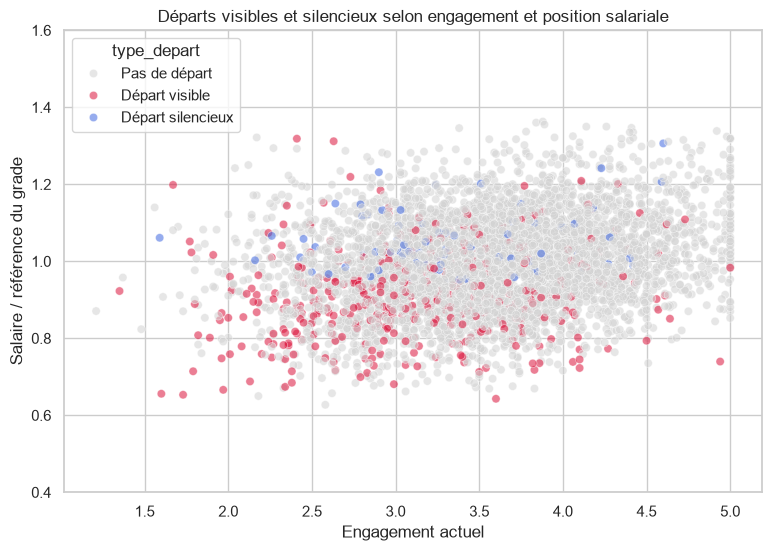

In [11]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=train_prepare,
    x="engagement_actuel",
    y="ratio_salaire_reference",
    hue="type_depart",
    alpha=0.55,
    palette={
        "Pas de départ": "lightgray",
        "Départ visible": "crimson",
        "Départ silencieux": "royalblue"
    }
)
plt.ylim(0.4, 1.6)
plt.title("Départs visibles et silencieux selon engagement et position salariale")
plt.xlabel("Engagement actuel")
plt.ylabel("Salaire / référence du grade")
plt.show()

# Partie B — Comparaison des modèles

## 12. Construction de trois ensembles de variables

Les modèles comparés sont :

1. baseline métier ;
2. baseline avec clustering ;
3. modèle hybride avec clustering et quatre signaux comportementaux.

In [12]:
colonnes_retrait = [
    "target", "type_depart", "signal_visible", "id", "date_reference",
    "date_naissance", "date_embauche", "date_derniere_promotion", "date_derniere_absence"
]
variables_cluster_modele = ["cluster_rh", "distance_cluster", "marge_cluster", "score_anomalie"]
variables_comportement_modele = [
    "engagement_faible", "salaire_sous_reference",
    "mecanisme_desengagement", "mecanisme_stagnation"
]

X_hybride = train_prepare.drop(columns=colonnes_retrait)
X_cluster_seul = X_hybride.drop(columns=variables_comportement_modele)
X_baseline = X_cluster_seul.drop(columns=variables_cluster_modele)
y = train_prepare["target"]

print("Variables baseline :", X_baseline.shape[1])
print("Variables avec clustering :", X_cluster_seul.shape[1])
print("Variables hybrides :", X_hybride.shape[1])

Variables baseline : 57
Variables avec clustering : 61
Variables hybrides : 65


## 13. Fonction d’entraînement et d’évaluation

In [13]:
def evaluer_modele(X_modele, nom):
    X_train = X_modele.loc[masque_train].copy()
    X_val = X_modele.loc[masque_validation].copy()
    y_train = y.loc[masque_train]
    y_val = y.loc[masque_validation]

    cat_cols = X_train.select_dtypes(include=["object", "string"]).columns.tolist()

    modele = CatBoostClassifier(
        iterations=1500,
        learning_rate=0.03,
        depth=6,
        l2_leaf_reg=7,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights="Balanced",
        random_seed=42,
        verbose=False
    )
    modele.fit(
        X_train, y_train,
        cat_features=cat_cols,
        eval_set=(X_val, y_val),
        early_stopping_rounds=150
    )

    proba = modele.predict_proba(X_val)[:, 1]
    lignes = []
    for seuil in np.arange(0.20, 0.81, 0.01):
        pred = (proba >= seuil).astype(int)
        lignes.append({
            "seuil": round(float(seuil), 2),
            "f1": f1_score(y_val, pred),
            "precision": precision_score(y_val, pred, zero_division=0),
            "rappel": recall_score(y_val, pred, zero_division=0)
        })
    scores = pd.DataFrame(lignes)
    meilleur = scores.loc[scores["f1"].idxmax()]
    pred = (proba >= meilleur["seuil"]).astype(int)

    resume = {
        "modele": nom,
        "iteration": modele.get_best_iteration(),
        "auc": roc_auc_score(y_val, proba),
        "seuil": meilleur["seuil"],
        "f1": meilleur["f1"],
        "precision": meilleur["precision"],
        "rappel": meilleur["rappel"]
    }
    return modele, proba, pred, scores, resume

## 14. Exécution des trois expériences

In [14]:
modele_base, proba_base, pred_base, seuils_base, resume_base = evaluer_modele(X_baseline, "Baseline")
modele_cluster, proba_cluster, pred_cluster, seuils_cluster, resume_cluster = evaluer_modele(X_cluster_seul, "Clustering")
modele_hybride, proba_hybride, pred_hybride, seuils_hybride, resume_hybride = evaluer_modele(X_hybride, "Hybride")

comparaison_modeles = pd.DataFrame([resume_base, resume_cluster, resume_hybride])
display(comparaison_modeles.sort_values("f1", ascending=False))

,modele,iteration,auc,seuil,f1,precision,rappel
1,Clustering,249,0.715841,0.59,0.323450,0.247934,0.465116
2,Hybride,366,0.726118,0.54,0.310000,0.228782,0.480620
0,Baseline,191,0.718804,0.57,0.304348,0.234310,0.434109


## 15. Mesure spécifique sur les départs visibles et silencieux

Un bon modèle global peut rester faible sur les départs silencieux. Cette cellule calcule le rappel séparément pour les deux formes de départ.

,modele,type_depart,effectif,rappel
0,prediction_base,Départ visible,100,0.510000
1,prediction_base,Départ silencieux,29,0.172414
2,prediction_cluster,Départ visible,100,0.550000
3,prediction_cluster,Départ silencieux,29,0.172414
4,prediction_hybride,Départ visible,100,0.570000
5,prediction_hybride,Départ silencieux,29,0.172414


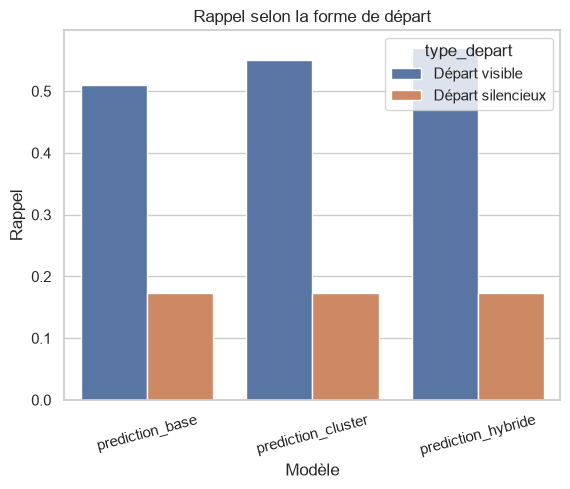

In [15]:
validation_detail = train_prepare.loc[masque_validation, ["target", "type_depart"]].copy()
validation_detail["prediction_base"] = pred_base
validation_detail["prediction_cluster"] = pred_cluster
validation_detail["prediction_hybride"] = pred_hybride

lignes = []
for nom_pred in ["prediction_base", "prediction_cluster", "prediction_hybride"]:
    for type_depart in ["Départ visible", "Départ silencieux"]:
        sous_ensemble = validation_detail["type_depart"] == type_depart
        lignes.append({
            "modele": nom_pred,
            "type_depart": type_depart,
            "effectif": int(sous_ensemble.sum()),
            "rappel": validation_detail.loc[sous_ensemble, nom_pred].mean()
        })

rappel_par_type = pd.DataFrame(lignes)
display(rappel_par_type)

sns.barplot(data=rappel_par_type, x="modele", y="rappel", hue="type_depart")
plt.title("Rappel selon la forme de départ")
plt.xlabel("Modèle")
plt.ylabel("Rappel")
plt.xticks(rotation=15)
plt.show()

## 16. Analyse des erreurs du modèle hybride

In [16]:
validation_detail["probabilite_hybride"] = proba_hybride
validation_detail["erreur_hybride"] = np.select(
    [
        (validation_detail["target"] == 1) & (validation_detail["prediction_hybride"] == 0),
        (validation_detail["target"] == 0) & (validation_detail["prediction_hybride"] == 1)
    ],
    ["Faux négatif", "Faux positif"],
    default="Correct"
)

display(pd.crosstab(validation_detail["type_depart"], validation_detail["erreur_hybride"]))

erreur_hybride,Correct,Faux négatif,Faux positif
type_depart,,,
Départ silencieux,5,24,0
Départ visible,57,43,0
Pas de départ,976,0,209


## 17. Importance des variables du modèle hybride

In [17]:
importance_hybride = pd.DataFrame({
    "variable": X_hybride.columns,
    "importance": modele_hybride.get_feature_importance()
}).sort_values("importance", ascending=False)

display(importance_hybride.head(30))

display(
    importance_hybride.loc[
        importance_hybride["variable"].isin(variables_cluster_modele + variables_comportement_modele)
    ]
)

,variable,importance
39,ratio_salaire_reference,7.019574
35,age,5.949778
12,engagement_actuel,5.507884
64,score_anomalie,5.396961
43,engagement_moyen,5.380553
40,ecart_salaire_reference,4.597345
62,distance_cluster,3.679693
36,anciennete,3.638516
44,evolution_engagement,2.875460
2,departement,2.686921


,variable,importance
64,score_anomalie,5.396961
62,distance_cluster,3.679693
61,cluster_rh,2.430393
63,marge_cluster,2.416426
57,engagement_faible,1.490960
60,mecanisme_stagnation,0.913921
58,salaire_sous_reference,0.709891
59,mecanisme_desengagement,0.703866


## 18. Conclusion automatique de l’expérience

La meilleure version est identifiée selon le F1, mais la décision finale doit aussi tenir compte du rappel sur les départs silencieux.

In [18]:
meilleur = comparaison_modeles.sort_values("f1", ascending=False).iloc[0]

print("Meilleur modèle :", meilleur["modele"])
print("F1 :", round(meilleur["f1"], 4))
print("AUC :", round(meilleur["auc"], 4))
print("Précision :", round(meilleur["precision"], 4))
print("Rappel :", round(meilleur["rappel"], 4))
print("Seuil :", round(meilleur["seuil"], 2))

Meilleur modèle : Clustering
F1 : 0.3235
AUC : 0.7158
Précision : 0.2479
Rappel : 0.4651
Seuil : 0.59


## 19. Export des résultats

In [19]:
comparaison_modeles.to_csv("../reports/comparaison_modele_hybride.csv", index=False)
profil_types_depart.to_csv("../reports/profils_departs_visibles_silencieux.csv")
rappel_par_type.to_csv("../reports/rappel_par_type_depart.csv", index=False)
importance_hybride.to_csv("../reports/importance_modele_hybride.csv", index=False)

export_validation = train_prepare.loc[masque_validation, ["id", "target", "type_depart"]].copy()
export_validation["probabilite_hybride"] = proba_hybride
export_validation["prediction_hybride"] = pred_hybride
export_validation.to_csv("../reports/validation_depart_visible_silencieux.csv", index=False)

print("Exports terminés dans reports.")

Exports terminés dans reports.


## Conclusion générale

Le modèle hybride ne sera considéré comme supérieur que s’il améliore le F1 temporel sans détériorer fortement la détection des départs silencieux.

Si les départs silencieux restent peu détectés, cela indiquera probablement une limite informationnelle du jeu de données : certains départs peuvent dépendre de facteurs absents des données, comme les opportunités externes, le management direct, la mobilité familiale ou les projets personnels.